# 04 · Segmentación de clientes y productos — SportSmart Perú

¿Qué segmentos de clientes existen, cuáles tienen mayor valor y qué productos se comportan de forma similar?

**Criterio de éxito:** silhouette > 0,4 con 3 segmentos interpretables. Se agrupa a los compradores; los clientes sin compra válida no tienen RFM.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from src.models import clustering
from src.data.estilo_graficos import AGUA, AZUL, GRIS, NARANJA, SUPERFICIE, TENUE, TINTA, aplicar_estilo, barras_h, guardar, numero
aplicar_estilo()
res = clustering.main()

## 1. Número de segmentos

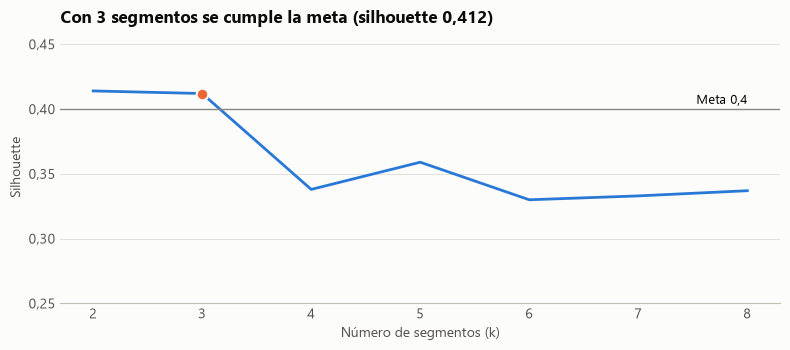

,k,inercia,silhouette,davies_bouldin,calinski_harabasz
0,2,12666.3,0.414,0.974,6640.5
1,3,9014.1,0.412,0.917,6247.0
2,4,7087.9,0.338,0.950,6003.1
3,5,5529.9,0.359,0.835,6319.8
4,6,4742.5,0.330,0.887,6153.9
5,7,4124.2,0.333,0.914,6091.3
6,8,3677.1,0.337,0.852,5990.7


In [2]:
b = pd.DataFrame(res['barrido_rfm']); s3 = float(b.loc[b.k == 3, 'silhouette'].iloc[0])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(b.k, b.silhouette, color=AZUL, lw=2)
ax.scatter([3], [s3], s=70, color=NARANJA, edgecolor=SUPERFICIE, linewidth=1.5, zorder=3)
ax.axhline(res['meta_silhouette'], color=TENUE, lw=1); ax.text(8, res['meta_silhouette'] + .004, 'Meta 0,4', ha='right', fontsize=9)
ax.set_ylim(.25, .46); ax.set_yticks([.25, .30, .35, .40, .45]); ax.set_xlabel('Número de segmentos (k)'); ax.set_ylabel('Silhouette')
ax.yaxis.set_major_formatter(lambda v, _: numero(v, 2))
ax.set_title(f"Con 3 segmentos se cumple la meta (silhouette {numero(s3, 3)})")
guardar(fig, 'silhouette_k')
b

Dos segmentos dan un silhouette apenas mayor, pero no distinguen a los clientes valiosos que se fueron. Con 4 o más, la métrica cae bajo la meta.

## 2. Comparación de algoritmos

In [3]:
print('Concordancia K-Means y jerárquico (ARI):', res['concordancia_kmeans_jerarquico_ari'], '| Estabilidad:', res['estabilidad_k3'])
display(pd.DataFrame(res['barrido_dbscan']))
pd.DataFrame(res['comparacion']).T

Concordancia K-Means y jerárquico (ARI): 0.558 | Estabilidad: {'ari_medio_semillas': 0.998, 'ari_medio_submuestras': 0.986, 'ari_min_submuestras': 0.959}


,eps,grupos,ruido_pct,silhouette
0,0.20,10,23.7,0.048
1,0.25,6,11.4,0.036
2,0.30,3,6.8,0.162
3,0.35,3,3.6,0.240
4,0.40,3,2.2,0.235
5,0.50,1,0.5,NaN


,silhouette,davies_bouldin,calinski_harabasz,grupos,ruido_pct
K-Means RFM (k=3),0.412,0.917,6247.0,3.0,0.0
K-Means LRFM (k=3),0.383,1.019,6824.2,3.0,0.0
Jerárquico Ward RFM (k=3),0.383,0.958,5114.7,3.0,0.0
DBSCAN RFM (eps=0.35),0.240,0.801,1930.6,3.0,3.6


## 3. Perfil de los segmentos

segmento,Alto valor activos,Valiosos inactivos,Ocasionales inactivos
clientes,1164.0,2598.0,4050.0
pct_clientes,14.9,33.3,51.8
pct_ventas,31.6,57.0,11.4
recencia,18.0,572.0,597.0
frecuencia,10.0,9.0,2.0
monetario,2177.0,2109.4,335.6
ticket_medio,235.1,238.9,176.6
clv,540.3,267.4,51.3
activos_180d,100.0,11.9,19.7
n_subcategorias,8.1,8.0,2.6


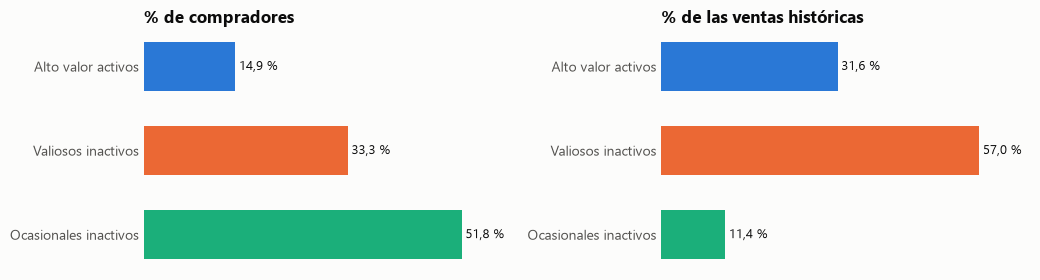

In [4]:
p = pd.DataFrame(res['perfil_segmentos']).set_index('segmento')
display(p[['clientes', 'pct_clientes', 'pct_ventas', 'recencia', 'frecuencia', 'monetario', 'ticket_medio', 'clv', 'activos_180d', 'n_subcategorias', 'pct_retraso', 'edad']].T.round(1))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 2.9))
col = [AZUL, NARANJA, AGUA]
barras_h(a1, list(p.index), list(p.pct_clientes), col, lambda v: numero(v) + ' %'); a1.set_title('% de compradores')
barras_h(a2, list(p.index), list(p.pct_ventas), col, lambda v: numero(v) + ' %'); a2.set_title('% de las ventas históricas')
guardar(fig, 'segmentos_valor')

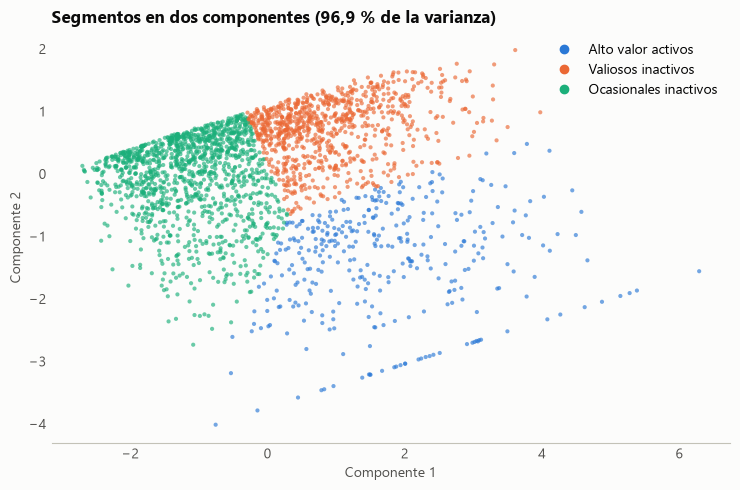

In [5]:
d = pd.DataFrame({k: res['pca'][k] for k in ('x', 'y', 'segmento')})
fig, ax = plt.subplots(figsize=(7.5, 5)); ax.grid(False)
col_seg = dict(zip(p.index, col))
ax.scatter(d.x, d.y, s=9, c=d.segmento.map(col_seg), alpha=.65, linewidths=0)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=c, label=n) for n, c in col_seg.items()], loc='best')
ax.set_xlabel('Componente 1'); ax.set_ylabel('Componente 2')
ax.set_title(f"Segmentos en dos componentes ({numero(res['pca']['varianza_2d_pct'])} % de la varianza)")
guardar(fig, 'segmentos_pca')

## 4. Clientes atípicos según DBSCAN

In [6]:
pd.Series(res['atipicos_dbscan'], name='valor').to_frame()

,valor
clientes,282.00
monetario_mediana,2448.86
monetario_mediana_resto,789.97
frecuencia_mediana,12.00
frecuencia_mediana_resto,4.00
pct_ventas,14.50


## 5. Productos con comportamiento similar

In [7]:
pr = res['productos']; print(pr['k'], pr['silhouette']); print('ABC por grupo:', pr['abc_por_grupo'])
pd.DataFrame(pr['perfil'])

2 {'silhouette': 0.241, 'davies_bouldin': 1.661, 'calinski_harabasz': 102.6}
ABC por grupo: {0: {'A': 160, 'B': 36, 'C': 0}, 1: {'A': 2, 'B': 50, 'C': 73}}


,grupo,productos,ingresos,unidades,precio,cv,devolucion_pct,ingresos_total,pct_ingresos
0,0,196,52933.87,381.5,119.9,0.43,7.60,12176917.03,87.05
1,1,125,13599.35,139.0,112.9,0.66,6.38,1811110.84,12.95


## 6. Conclusiones y acciones

- **Meta cumplida:** K-Means sobre RFM logra silhouette de 0,412 con 3 segmentos, y es muy estable (ARI de 0,986 al repetir con 80 % de los clientes). RFM supera a LRFM (0,383) y al jerárquico (0,383).
- **DBSCAN** obtiene 0,240 y no sirve para segmentar, pero identifica 282 clientes atípicos (3,6 %): gastan 3,1 veces más que el resto en la mediana y aportan 14,5 % de las ventas. Son clientes VIP, no errores.
- **Productos:** se forman 2 grupos, de alta y baja rotación, con silhouette de solo 0,241. La estructura es débil y se apoya en la clasificación ABC: 160 de los 196 productos del grupo de alta rotación son clase A.

| Segmento | Compradores | Ventas históricas | Perfil (medianas) | Acción propuesta |
|---|---|---|---|---|
| Alto valor activos | 14,9 % | 31,6 % | 18 días sin comprar, 10 pedidos, S/ 2 177 | Fidelización y beneficios exclusivos |
| Valiosos inactivos | 33,3 % | 57,0 % | 572 días sin comprar, 9 pedidos, S/ 2 109 | Campañas de recuperación, priorizadas por valor |
| Ocasionales inactivos | 51,8 % | 11,4 % | 597 días sin comprar, 2 pedidos, S/ 336 | Incentivo de bajo costo para la segunda compra |

La edad casi no cambia entre segmentos (31,1 a 31,3 años), lo que confirma que conviene segmentar por comportamiento.

**Limitaciones:** los 7 188 clientes sin compra válida quedan fuera, y su activación se mide con un KPI aparte. El CLV usa una retención global, por lo que sobreestima a quienes llevan mucho tiempo inactivos.